# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [94]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [95]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [96]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [97]:
# Write your code here to read the data
data = pd.read_csv('/content/drive/MyDrive/AIML/Project1/foodhub_order.csv')

In [98]:
# Write your code here to view the first 5 rows
df=data.copy()
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [99]:
# Write your code here
df.shape

(1898, 9)

#### Observations:
There are 1898 rows and 9 columns

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [100]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
- order_id, customer_id, food_preparation_time and delivery_time columns have int64 (Integer) datatype
- restaurant_name, cuisine_type, day_of_the_week and rating columns have object data type
- cost_of_the_order column is float64 (Float) datatype


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [101]:
# Write your code here
df.isnull().sum()


,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


In [102]:
for col in df:
  print(df[col].value_counts(normalize=True, dropna=False)) #check to identify unique values in each column and their normalized distribution
  print("------")

order_id
1478056    0.000527
1477147    0.000527
1477685    0.000527
1477070    0.000527
1477334    0.000527
             ...   
1478198    0.000527
1477449    0.000527
1476966    0.000527
1478437    0.000527
1477895    0.000527
Name: proportion, Length: 1898, dtype: float64
------
customer_id
52832     0.006849
47440     0.005269
83287     0.004742
250494    0.004215
259341    0.003688
            ...   
143926    0.000527
89574     0.000527
157711    0.000527
66393     0.000527
358141    0.000527
Name: proportion, Length: 1200, dtype: float64
------
restaurant_name
Shake Shack                  0.115385
The Meatball Shop            0.069547
Blue Ribbon Sushi            0.062698
Blue Ribbon Fried Chicken    0.050580
Parm                         0.035827
                               ...   
Rye House                    0.000527
Hiroko's Place               0.000527
Frank Restaurant             0.000527
Sarabeth's West              0.000527
'wichcraft                   0.000527
Name: pr

In [103]:
for col in df:
  print(df[col].unique())#check to identify null
  print (df[col].nunique())
  print("------")

[1477147 1477685 1477070 ... 1477819 1477513 1478056]
1898
------
[337525 358141  66393 ...  97838 292602 397537]
1200
------
['Hangawi' 'Blue Ribbon Sushi Izakaya' 'Cafe Habana'
 'Blue Ribbon Fried Chicken' 'Dirty Bird to Go' 'Tamarind TriBeCa'
 'The Meatball Shop' 'Barbounia' 'Anjappar Chettinad' 'Bukhara Grill'
 'Big Wong Restaurant \x8c_¤¾Ñ¼' 'Empanada Mama (closed)' 'Pylos'
 "Lucky's Famous Burgers" 'Shake Shack' 'Sushi of Gari' 'RedFarm Hudson'
 'Blue Ribbon Sushi' 'Five Guys Burgers and Fries' 'Tortaria'
 'Cafe Mogador' 'Otto Enoteca Pizzeria' 'Vezzo Thin Crust Pizza'
 'Sushi of Gari 46' 'The Kati Roll Company' 'Klong' '5 Napkin Burger'
 'TAO' 'Parm' 'Sushi Samba' 'Haru Gramercy Park'
 'Chipotle Mexican Grill $1.99 Delivery' 'RedFarm Broadway' 'Cafeteria'
 'DuMont Burger' "Sarabeth's East" 'Hill Country Fried Chicken' 'Bistango'
 "Jack's Wife Freda" "Mamoun's Falafel" 'Prosperity Dumpling'
 'Blue Ribbon Sushi Bar & Grill' 'Westville Hudson' 'Blue Ribbon Brooklyn'
 'Nobu Next Doo

In [104]:
df.loc[df['rating']=='Not given']

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
6,1477894,157711,The Meatball Shop,Italian,6.07,Weekend,Not given,28,21
10,1477895,143926,Big Wong Restaurant _¤¾Ñ¼,Chinese,5.92,Weekday,Not given,34,28
14,1478198,62667,Lucky's Famous Burgers,American,12.13,Weekday,Not given,23,30
...,...,...,...,...,...,...,...,...,...
1887,1476873,237616,Shake Shack,American,5.82,Weekend,Not given,26,30
1891,1476981,138586,Shake Shack,American,5.82,Weekend,Not given,22,28
1892,1477473,97838,Han Dynasty,Chinese,29.15,Weekend,Not given,29,21
1895,1477819,35309,Blue Ribbon Sushi,Japanese,25.22,Weekday,Not given,31,24


In [105]:
df['rating'] = df['rating'].replace('Not given', np.nan)
df['rating'] = df['rating'].astype(float)

#### Observations:
- 1. First checked if there are any null or NaN vales by: "df.isnull().sum()
"
- 2. Then checked the unique values for each column and their normalized distrubution. Observed that rating column has 'Not given' which is a null value.
- 3. To double check, printed all unique values of each column
- 4. by df.loc..... tried to see how many values are not given and tried to see if there is any pattern. The number of missing data is significant, so can't replace with any statistical value.
- 5. So decided to replace 'Not given' with np.nan and change type of rating to float



In [106]:
df['rating'].value_counts(normalize=True, dropna=False)

,proportion
rating,
NaN,0.387777
5.0,0.309800
4.0,0.203372
3.0,0.099052


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [107]:
# Write your code here
df.describe().T
#df['food_preparation_time'].describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1898.0,1.477496e+06,548.049724,1476547.00,1477021.25,1477495.50,1.477970e+06,1478444.00
customer_id,1898.0,1.711685e+05,113698.139743,1311.00,77787.75,128600.00,2.705250e+05,405334.00
cost_of_the_order,1898.0,1.649885e+01,7.483812,4.47,12.08,14.14,2.229750e+01,35.41
rating,1162.0,4.344234e+00,0.741478,3.00,4.00,5.00,5.000000e+00,5.00
food_preparation_time,1898.0,2.737197e+01,4.632481,20.00,23.00,27.00,3.100000e+01,35.00
delivery_time,1898.0,2.416175e+01,4.972637,15.00,20.00,25.00,2.800000e+01,33.00


#### Observations:
For the food preparation time (indicated by: food_preparation_time),
Minimum time is 20 minutes
Average time is 27.37197 minutes
Maximum time is 35 minutes


### **Question 5:** How many orders are not rated? [1 mark]

In [108]:
# Write the code here
df['rating'].isnull().sum()

np.int64(736)

#### Observations:
736 ratings have null values based on previous calculations of reassigning 'Not given' to null. Hence, 736 orders are not rated

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

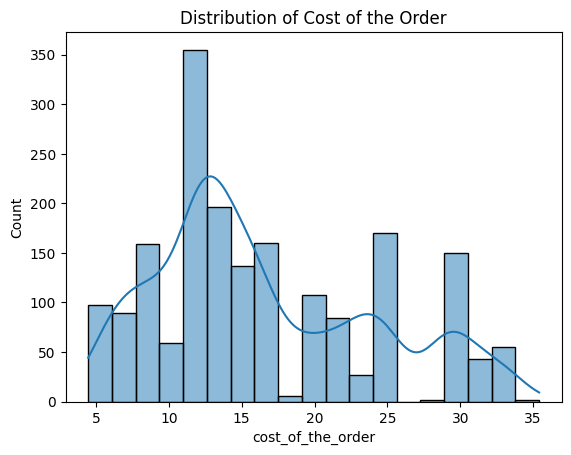

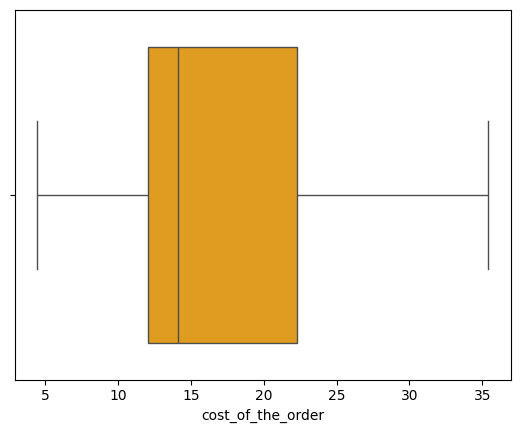

In [109]:
# Write the code here
#not plotting order_id and customer_id as they are ID columns
"""
#can plot it all together, but decided to it in different cells
numerical_columns = ['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating']

for plot in numerical_columns:
  sns.histplot(data = df, x = plot, kde=True)
  plt.title(f'Distribution of {plot}')
  plt.show()
  print("\n\n")

for plot in numerical_columns:
  sns.boxplot(data = df, x = plot, color='orange')
  plt.show()
  print("\n\n")
categorical_columns = [ 'restaurant_name', 'cuisine_type', 'day_of_the_week']

for col in categorical_columns:
  if col == 'restaurant_name':
    plt.figure(figsize=(40,10))
  sns.countplot(data = df, x=col, width=0.5)
  plt.xticks(rotation=90)
  plt.show()
  print("\n\n")
"""

sns.histplot(data = df, x = 'cost_of_the_order', kde=True)
plt.title(f'Distribution of Cost of the Order')
plt.show()

sns.boxplot(data = df, x = 'cost_of_the_order', color='orange')
plt.show()

#### **Observations:**
The plotting for **customer_id** and **order_id** is not done on univariant analysis as there is no significant insights that can be derived from IDs. The order_id are unique, where as customer_ids may be repeated as a customer can order more than once. However these columns would be useful for plotting for other use cases.

#### **Observations for cost of the order:**
- Based on the histogram,
  - The cost of the orders range around 0-40.
  - The kde peaks around 11-13 dollars (assuming that's the currency, given NYC) meaning most orders lie in that range.
  - There are around 350 orders in that price
- Based on the box plot,
  - The median cost is around 14.
  - The distribution is slightly right skewed.
  - There are no outliers.



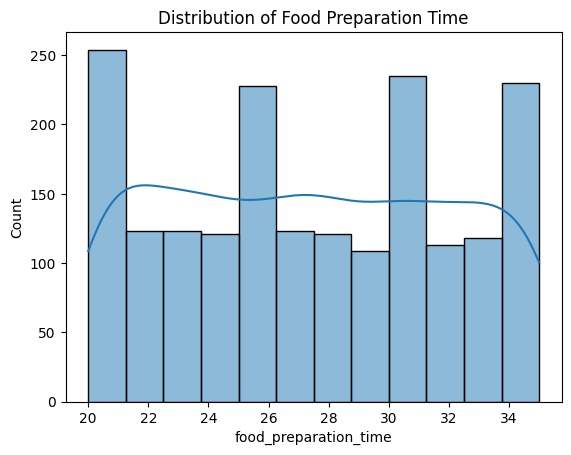

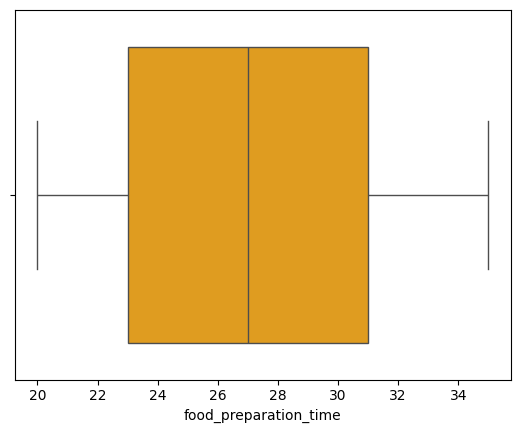

In [110]:
sns.histplot(data = df, x = 'food_preparation_time', kde=True)
plt.title(f'Distribution of Food Preparation Time')
plt.show()

sns.boxplot(data = df, x = 'food_preparation_time', color='orange')
plt.show()

#### **Observations for Food preparation time:**
- Based on the histogram,
  - The food preparation time ranges from 20-35 minutes.
  - More orders fall under the 4 timings: 20-21 min, 25-26 min, 30-31 min, 34-35min. The kde does not capture the peaks. The rest of the times are more or less evenly distributed.
- Based on the box plot,
  - The median prep time is 27 minutes.
  - The distribution looks evenly distributed.
  - There are no outliers.

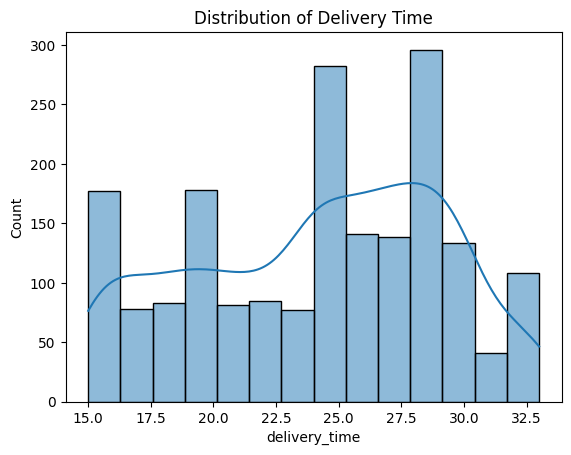

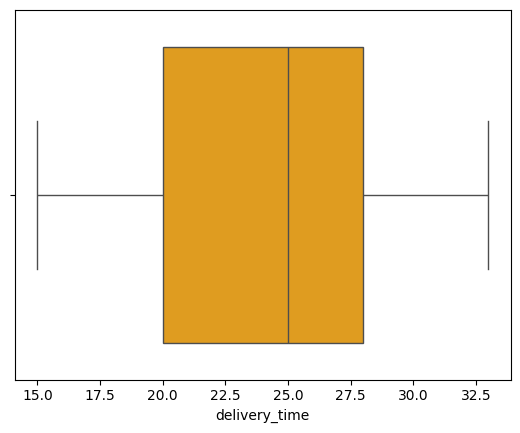

In [111]:
sns.histplot(data = df, x = 'delivery_time', kde=True)
plt.title(f'Distribution of Delivery Time')
plt.show()

sns.boxplot(data = df, x = 'delivery_time', color='orange')
plt.show()

#### **Observations for Delivery time:**
- Based on the histogram,
  - The delivery time peaks around 28-32 minutes.
  - Besides that, based on the kde, it is more or less evenly distributed without any major tails or skews
- Based on the box plot,
  - The median delivery time is 25 minutes.
  - The distribution looks evenly distributed, minimal left skew.
  - There are no outliers.

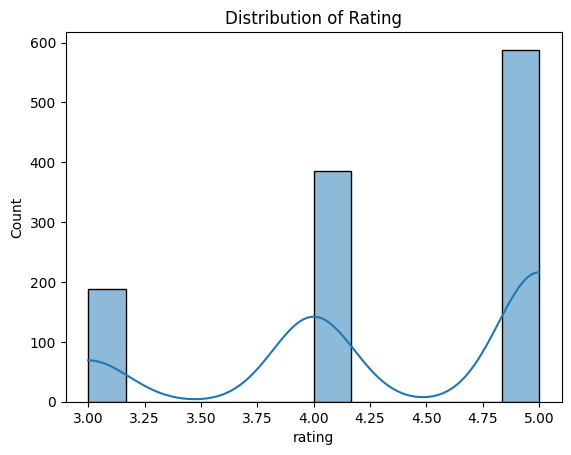

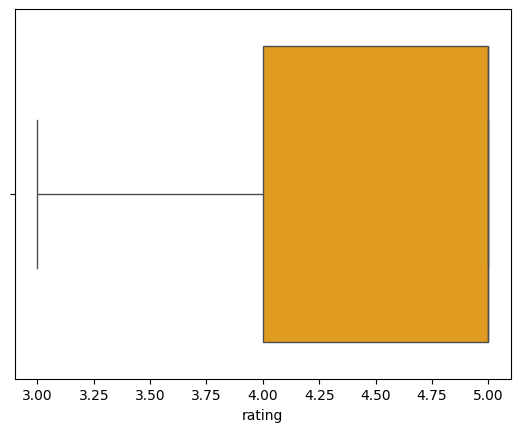

In [112]:
sns.histplot(data = df, x = 'rating', kde=True)
plt.title(f'Distribution of Rating')
plt.show()

sns.boxplot(data = df, x = 'rating', color='orange')
plt.show()

#### **Observations for Rating:**
- Based on the histogram,
  - The rating of the retaurant is pretty good since it has peak at 3,4,5 in a rating of 0-5, with maximum ratings close to 5.
  - There are missing values but they are not plotted
- Based on the box plot,
  - The median rating is 5.
  - The distribution is heavily left skewed.
  - There are no outliers, but the ~736 missing values that we know from previous analysis are not plotted


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 140 (\x8c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 142 (\x8e) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


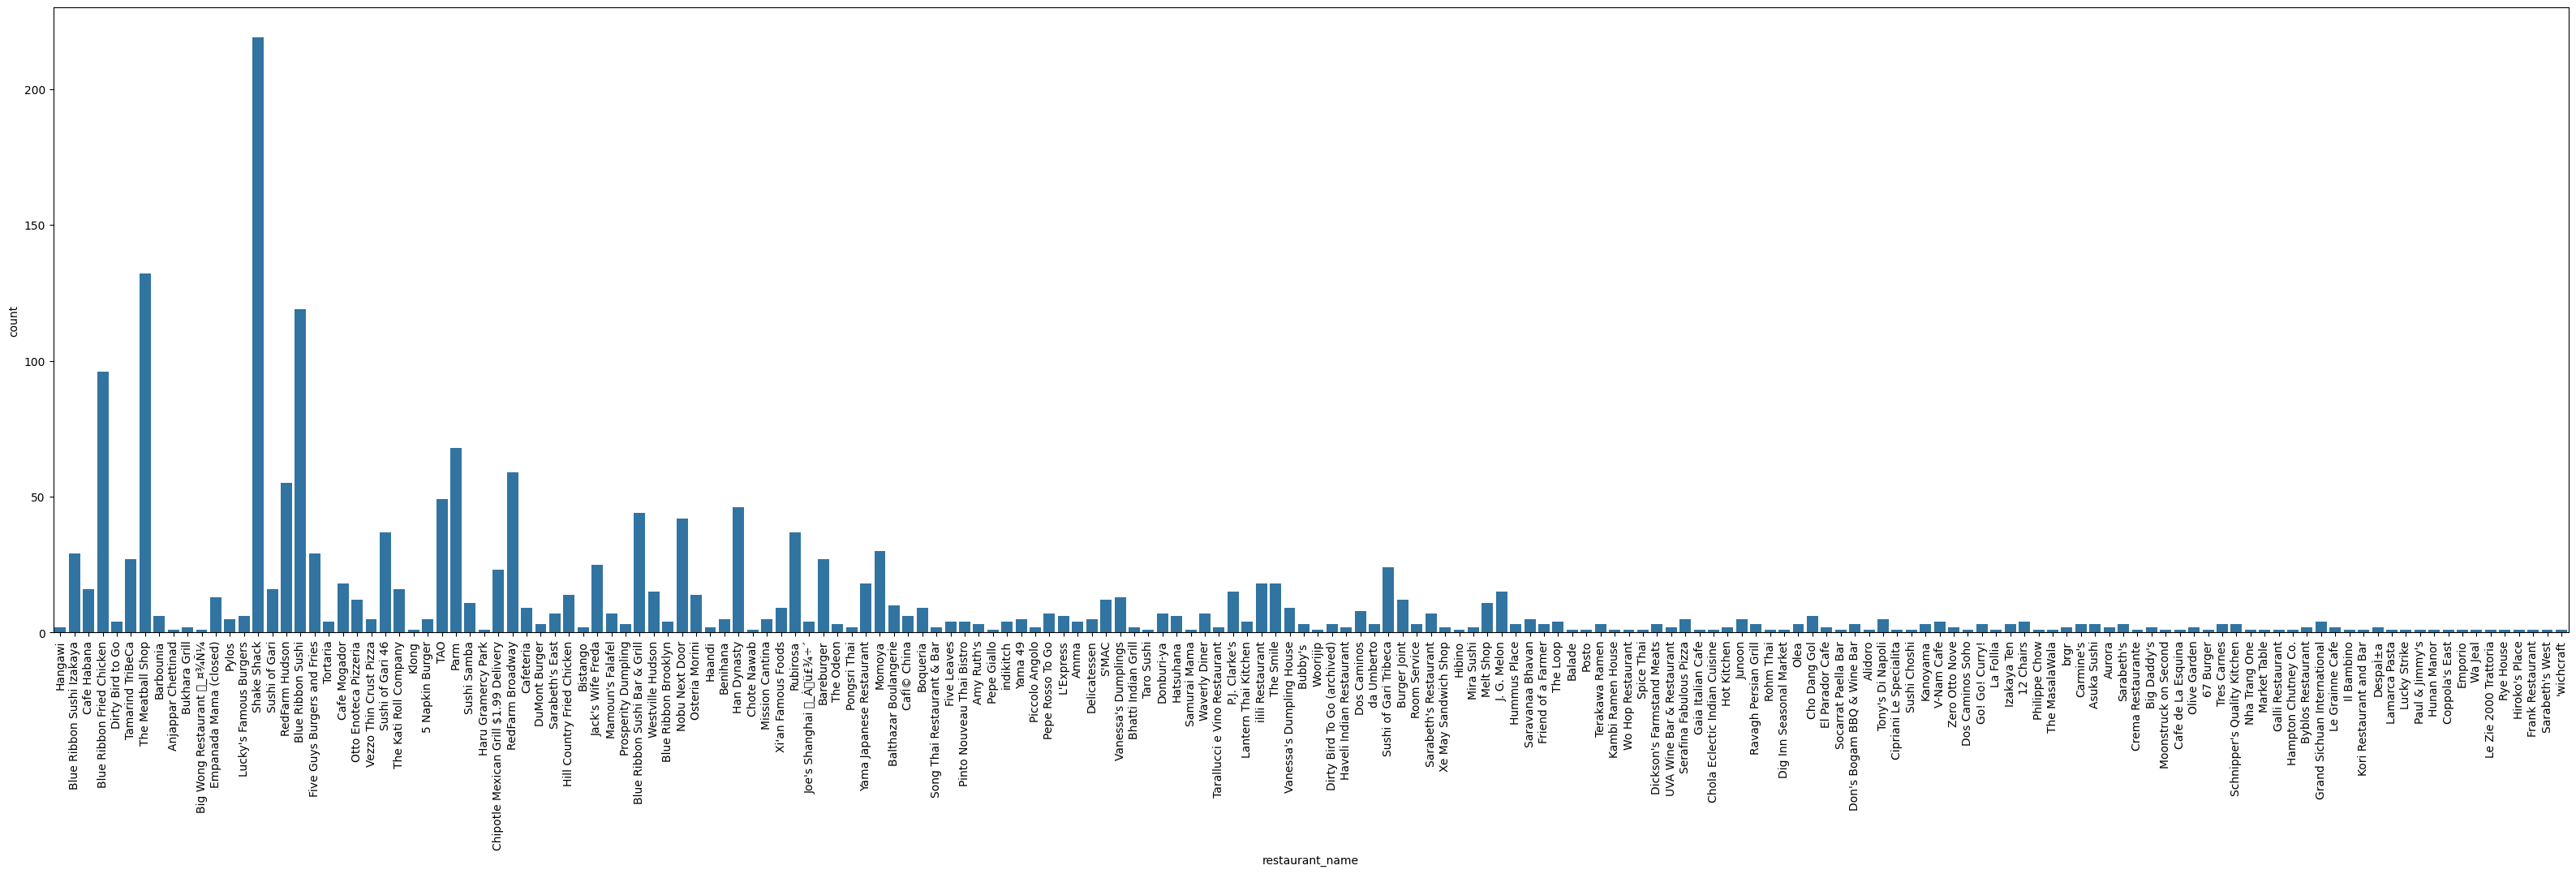

In [113]:
plt.figure(figsize=(40,10))
sns.countplot(data = df, x='restaurant_name')
plt.xticks(rotation=90)
plt.show()

#### **Observations on restaurant name**:
Based on the countplot,
- 'Shake Shack' has the highest orders, more than 200
- The next peak orders are from 'The Meatball Shop' (approx. 135) followed by 'Blue Ribbon Sushi(approx. 125).
- There are quite a few restaurants where the orders have been placed less than 5 times

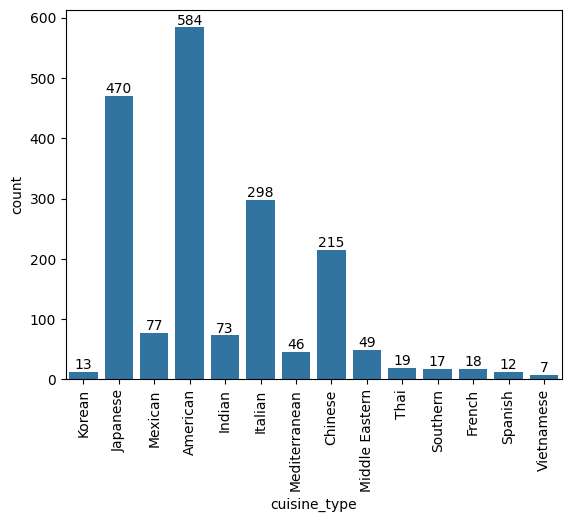

In [114]:
ax = sns.countplot(data = df, x='cuisine_type')
ax.bar_label(ax.containers[0])
plt.xticks(rotation=90)
plt.show()

#### **Observations on Cuisine Type:**
- 'American' cuisine is the most popular with around 584 records/orders.
- 'Vietnamese' is the least popular cuisine.
- The top 4 cuisines in popularity order are: American, Japanese, Italian, Chinese.
- All the rest of the cuisines have less than 100 orders.

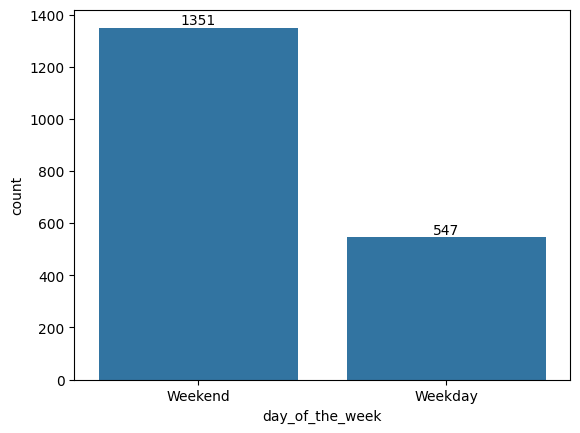

In [115]:
ax = sns.countplot(data = df, x='day_of_the_week')
ax.bar_label(ax.containers[0])
plt.show()

#### **Observations on Day of the week:**
- The values of this column are: Weekend and Weekday
- The number of orders are on weekends (1351) is more than double than that on weekday(547)

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [116]:
# Write the code here
df['restaurant_name'].value_counts().head(5)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:
The top 5 restaurants in the descending order of the number of orders received are:
1. Shake Shack
2. The Meatball Shop
3. Blue Ribbon Sushi
4. Blue Ribbon Fried Chicken
5. Parm


### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [117]:
# Write the code here
df[df['day_of_the_week']=='Weekend']['cuisine_type'].value_counts().head(1)

,count
cuisine_type,
American,415


#### Observations:
- 'American' cuisine is the most popular cuisine on weekends.
- Logic:
Filtered by Weekend > Then got the cuisine type column > applied value_counts() which will list the counts of each cuisine in descending order. > Got the head 1 record from this list.

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [118]:
# Write the code here
orders_more_than_20 = df[df['cost_of_the_order']>20].shape[0]
total_orders = df.shape[0]
percentage = orders_more_than_20/total_orders*100
print(f"The percentage of the orders cost more than 20 dollars is: {percentage: 0.3f}")

The percentage of the orders cost more than 20 dollars is:  29.241


#### Observations:
29.24% of orders cost more than 20 dollars

### **Question 10**: What is the mean order delivery time? [1 mark]

In [119]:
# Write the code here
df['delivery_time'].mean()

np.float64(24.161749209694417)

#### Observations:
The mean order delivery time is 24.16 minutes

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [120]:
# Write the code here
df['customer_id'].value_counts().head(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:
The top 3 most frequent customers and their respective number of orders are:
1. Customer id: 52832, Number of orders: 13
2. Customer id: 47440, Number of orders: 10
3. Customer id: 83287, Number of orders: 9


### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


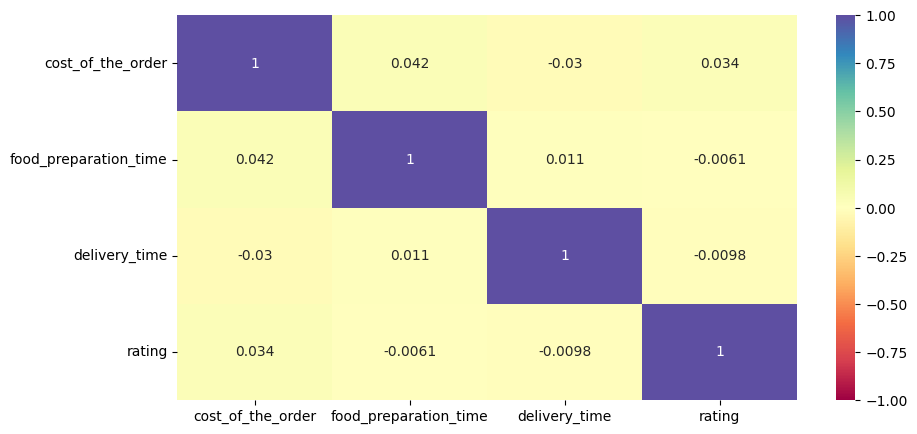

In [121]:
# Write the code here
#order_id, customer_id not included since it is unique id
numerical_columns = ['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating']
corr = df[numerical_columns].corr()
plt.figure(figsize=(10,5))
sns.heatmap(corr,annot=True,cmap='Spectral',vmin=-1,vmax=1)
plt.show()

#### **Observations**

- There is **no correlation** between any of the numerical values based on the heatmap as the correlation coefficient values are close to 0.
- Some of the *very weak correlations* observed using the heatmap is
 cost_of_the order <-> food_preparation_time (+ve)


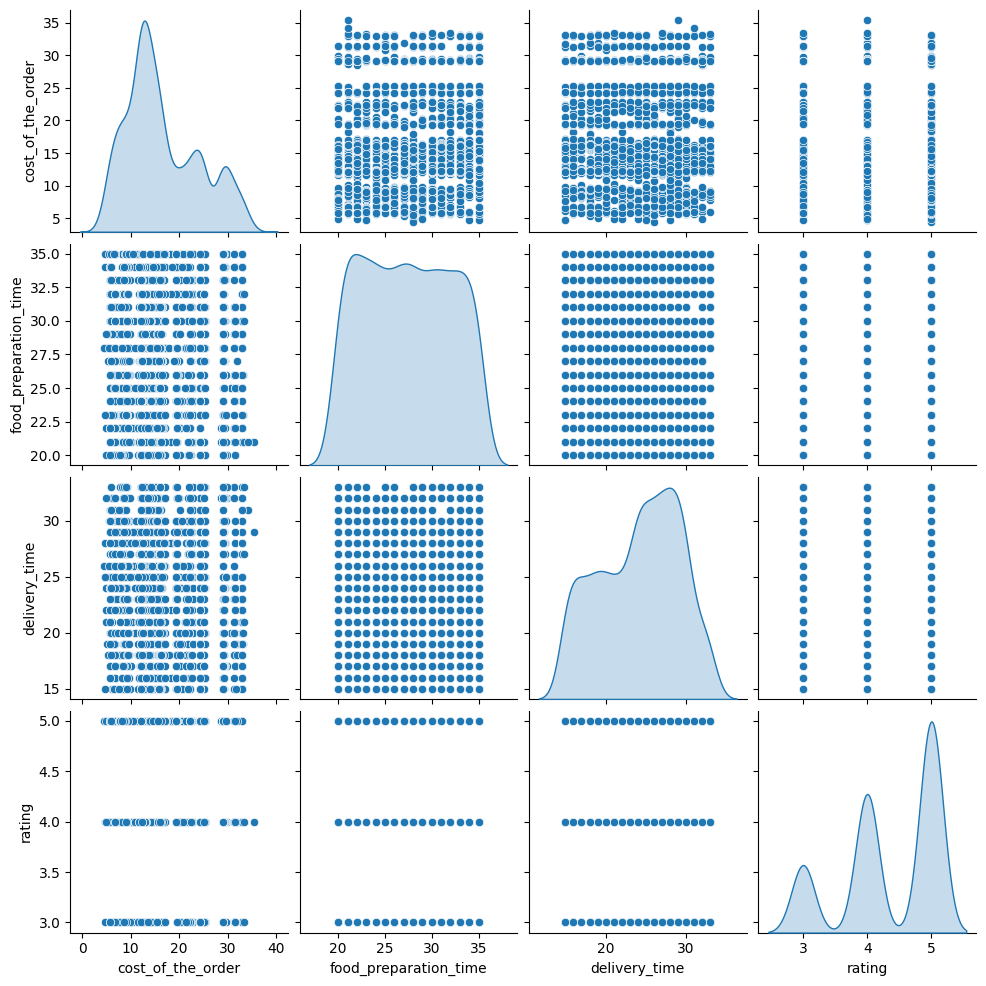

In [122]:
sns.pairplot(data=df[numerical_columns], diag_kind="kde")
plt.show()

### **Observations:**
The bivariant scatter plot on numerical columns also doesn't give much insight.

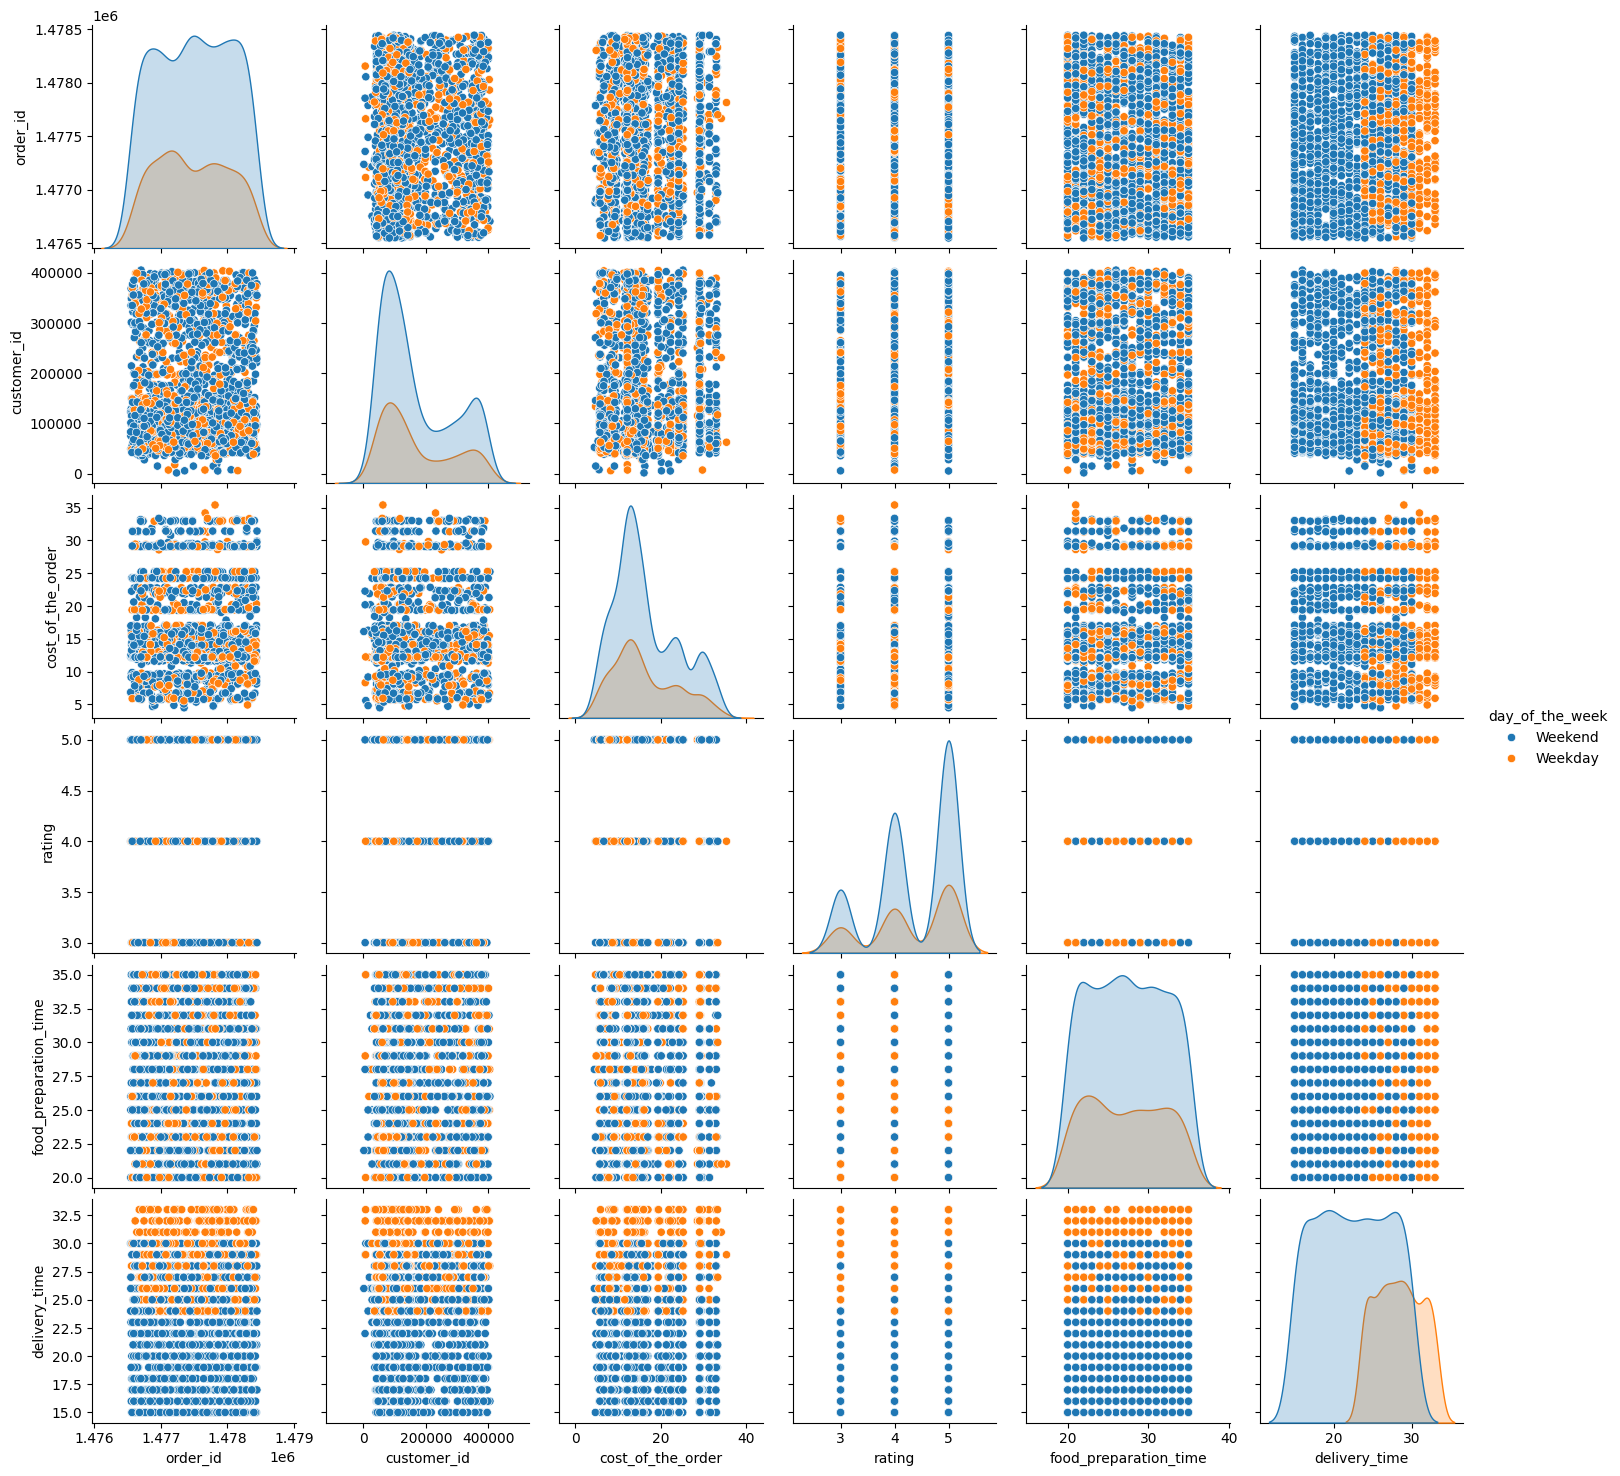

In [123]:
sns.pairplot(data=df, hue='day_of_the_week')
plt.show()

####Observations:
- Since there is no strong correlation among the numerical values, hence we cannot derive much from scatter plot too
- One thing observed is the delivery time on weekends is less than weekdays.
- There wont be much use of line plot also since there is no variable which changes over time drastically

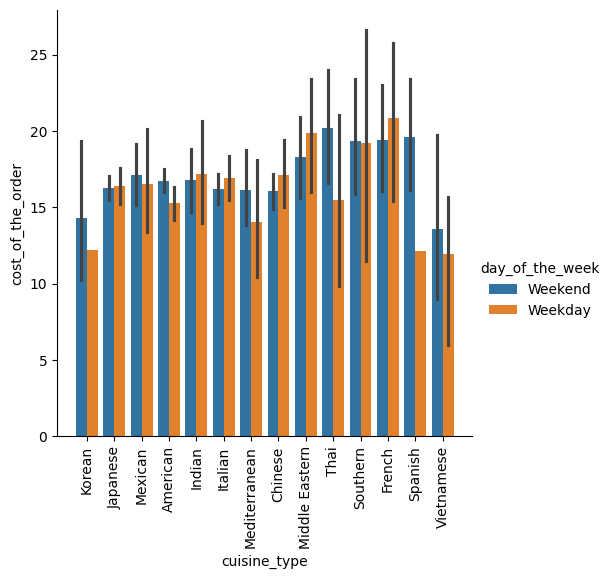

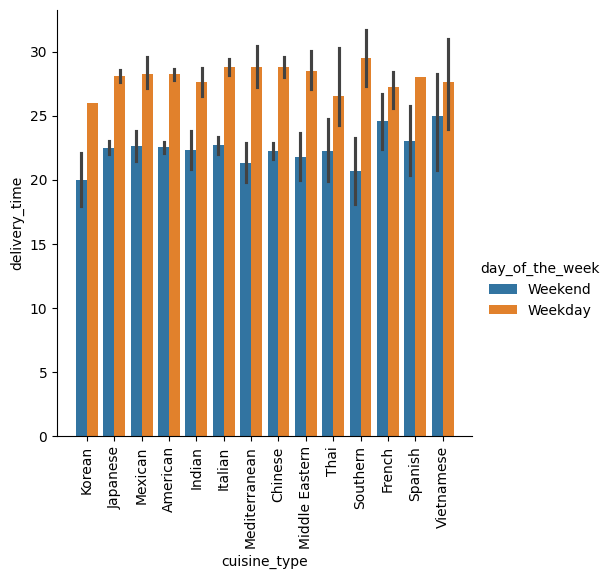

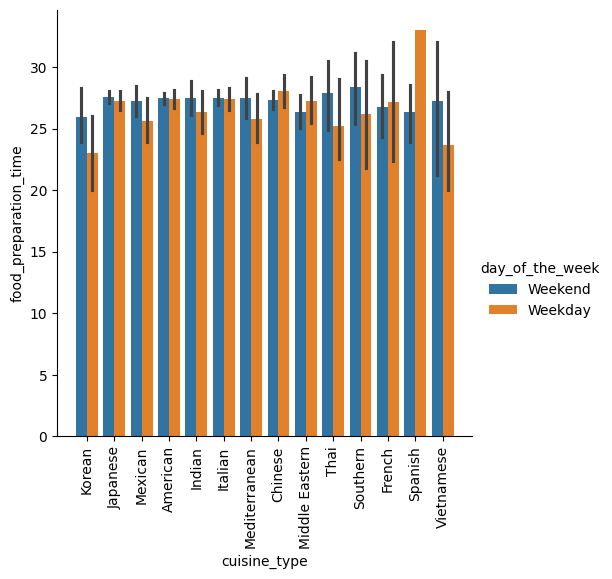

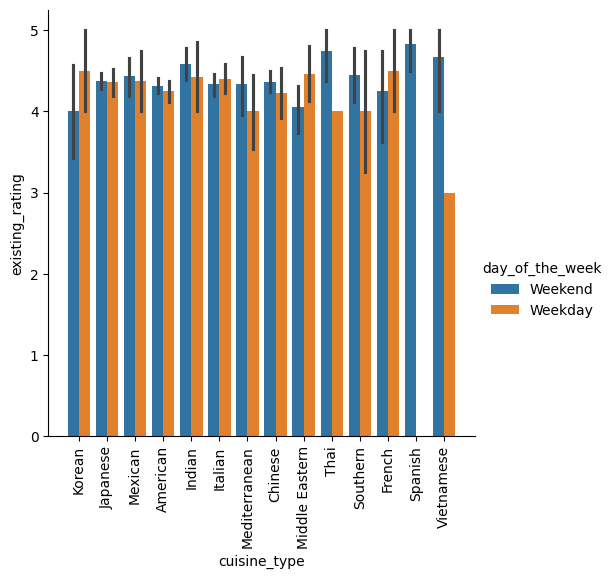

In [124]:
sns.catplot(data=df, kind="bar", x='cuisine_type', y='cost_of_the_order', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

sns.catplot(data=df, kind="bar", x='cuisine_type', y='delivery_time', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

sns.catplot(data=df, kind="bar", x='cuisine_type', y='food_preparation_time', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

df['existing_rating'] = df['rating'].dropna()
sns.catplot(data=df, kind="bar", x='cuisine_type', y='existing_rating', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

#### Observations:

- Based on the cat plot on cuisine_type plotted against various numerical columns, with the hue of: day_of_the_week,
  - The ***cost_of_the_order*** is lowest for weekdays orders of Vietnamese, Korean and Spanish cuisine restaurants
  - The ***delivery_time*** on weekends is relatively less than that on weekdays across all cuisines
  - Spanish cuisine restaurants have the highest ***food_preparation_time***  for weekdays, while Korean cuisine has the lowest.
  - There is no ***rating*** available for Spanish cuisine restaurants for weekdays.

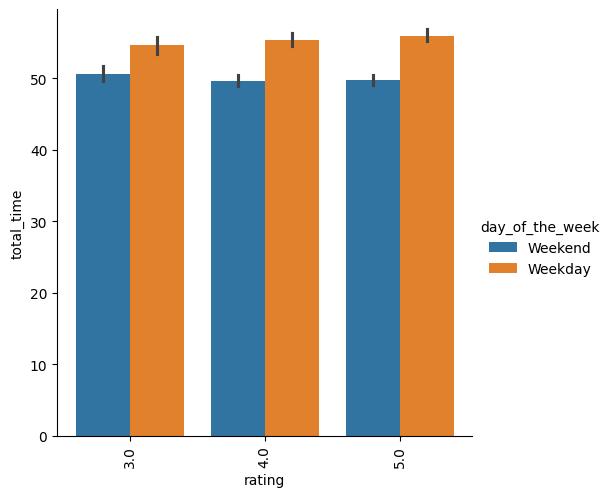

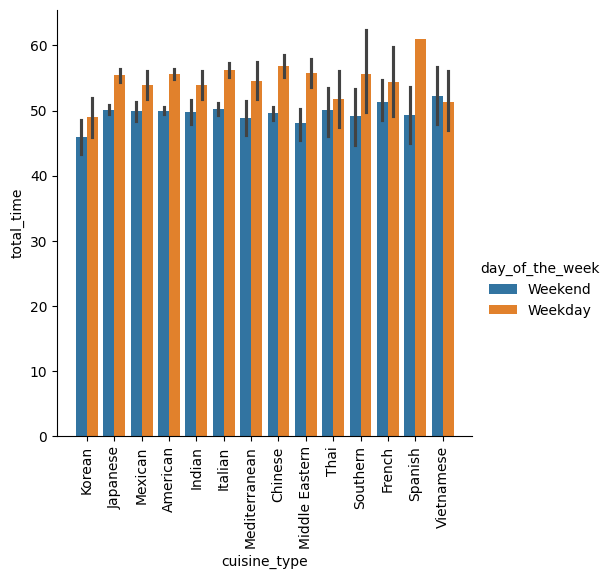

(array([30., 35., 40., 45., 50., 55., 60., 65., 70.]),
 [Text(30.0, 0, '30'),
  Text(35.0, 0, '35'),
  Text(40.0, 0, '40'),
  Text(45.0, 0, '45'),
  Text(50.0, 0, '50'),
  Text(55.0, 0, '55'),
  Text(60.0, 0, '60'),
  Text(65.0, 0, '65'),
  Text(70.0, 0, '70')])

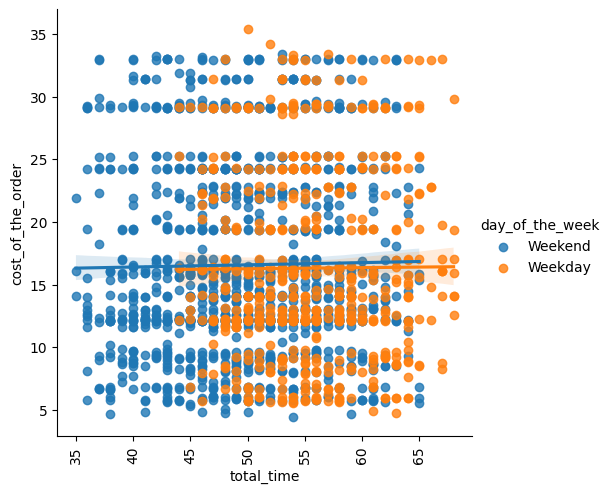

In [125]:
df['total_time'] = df['delivery_time'] + df['food_preparation_time']
new_numerical_columns = ['cost_of_the_order','food_preparation_time', 'delivery_time','total_time','rating']

sns.catplot(data=df, kind="bar", x='rating', y='total_time', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

sns.catplot(data=df, kind="bar", x='cuisine_type', y='total_time', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

sns.lmplot(data=df, x='total_time', y='cost_of_the_order', hue='day_of_the_week')
plt.xticks(rotation=90)


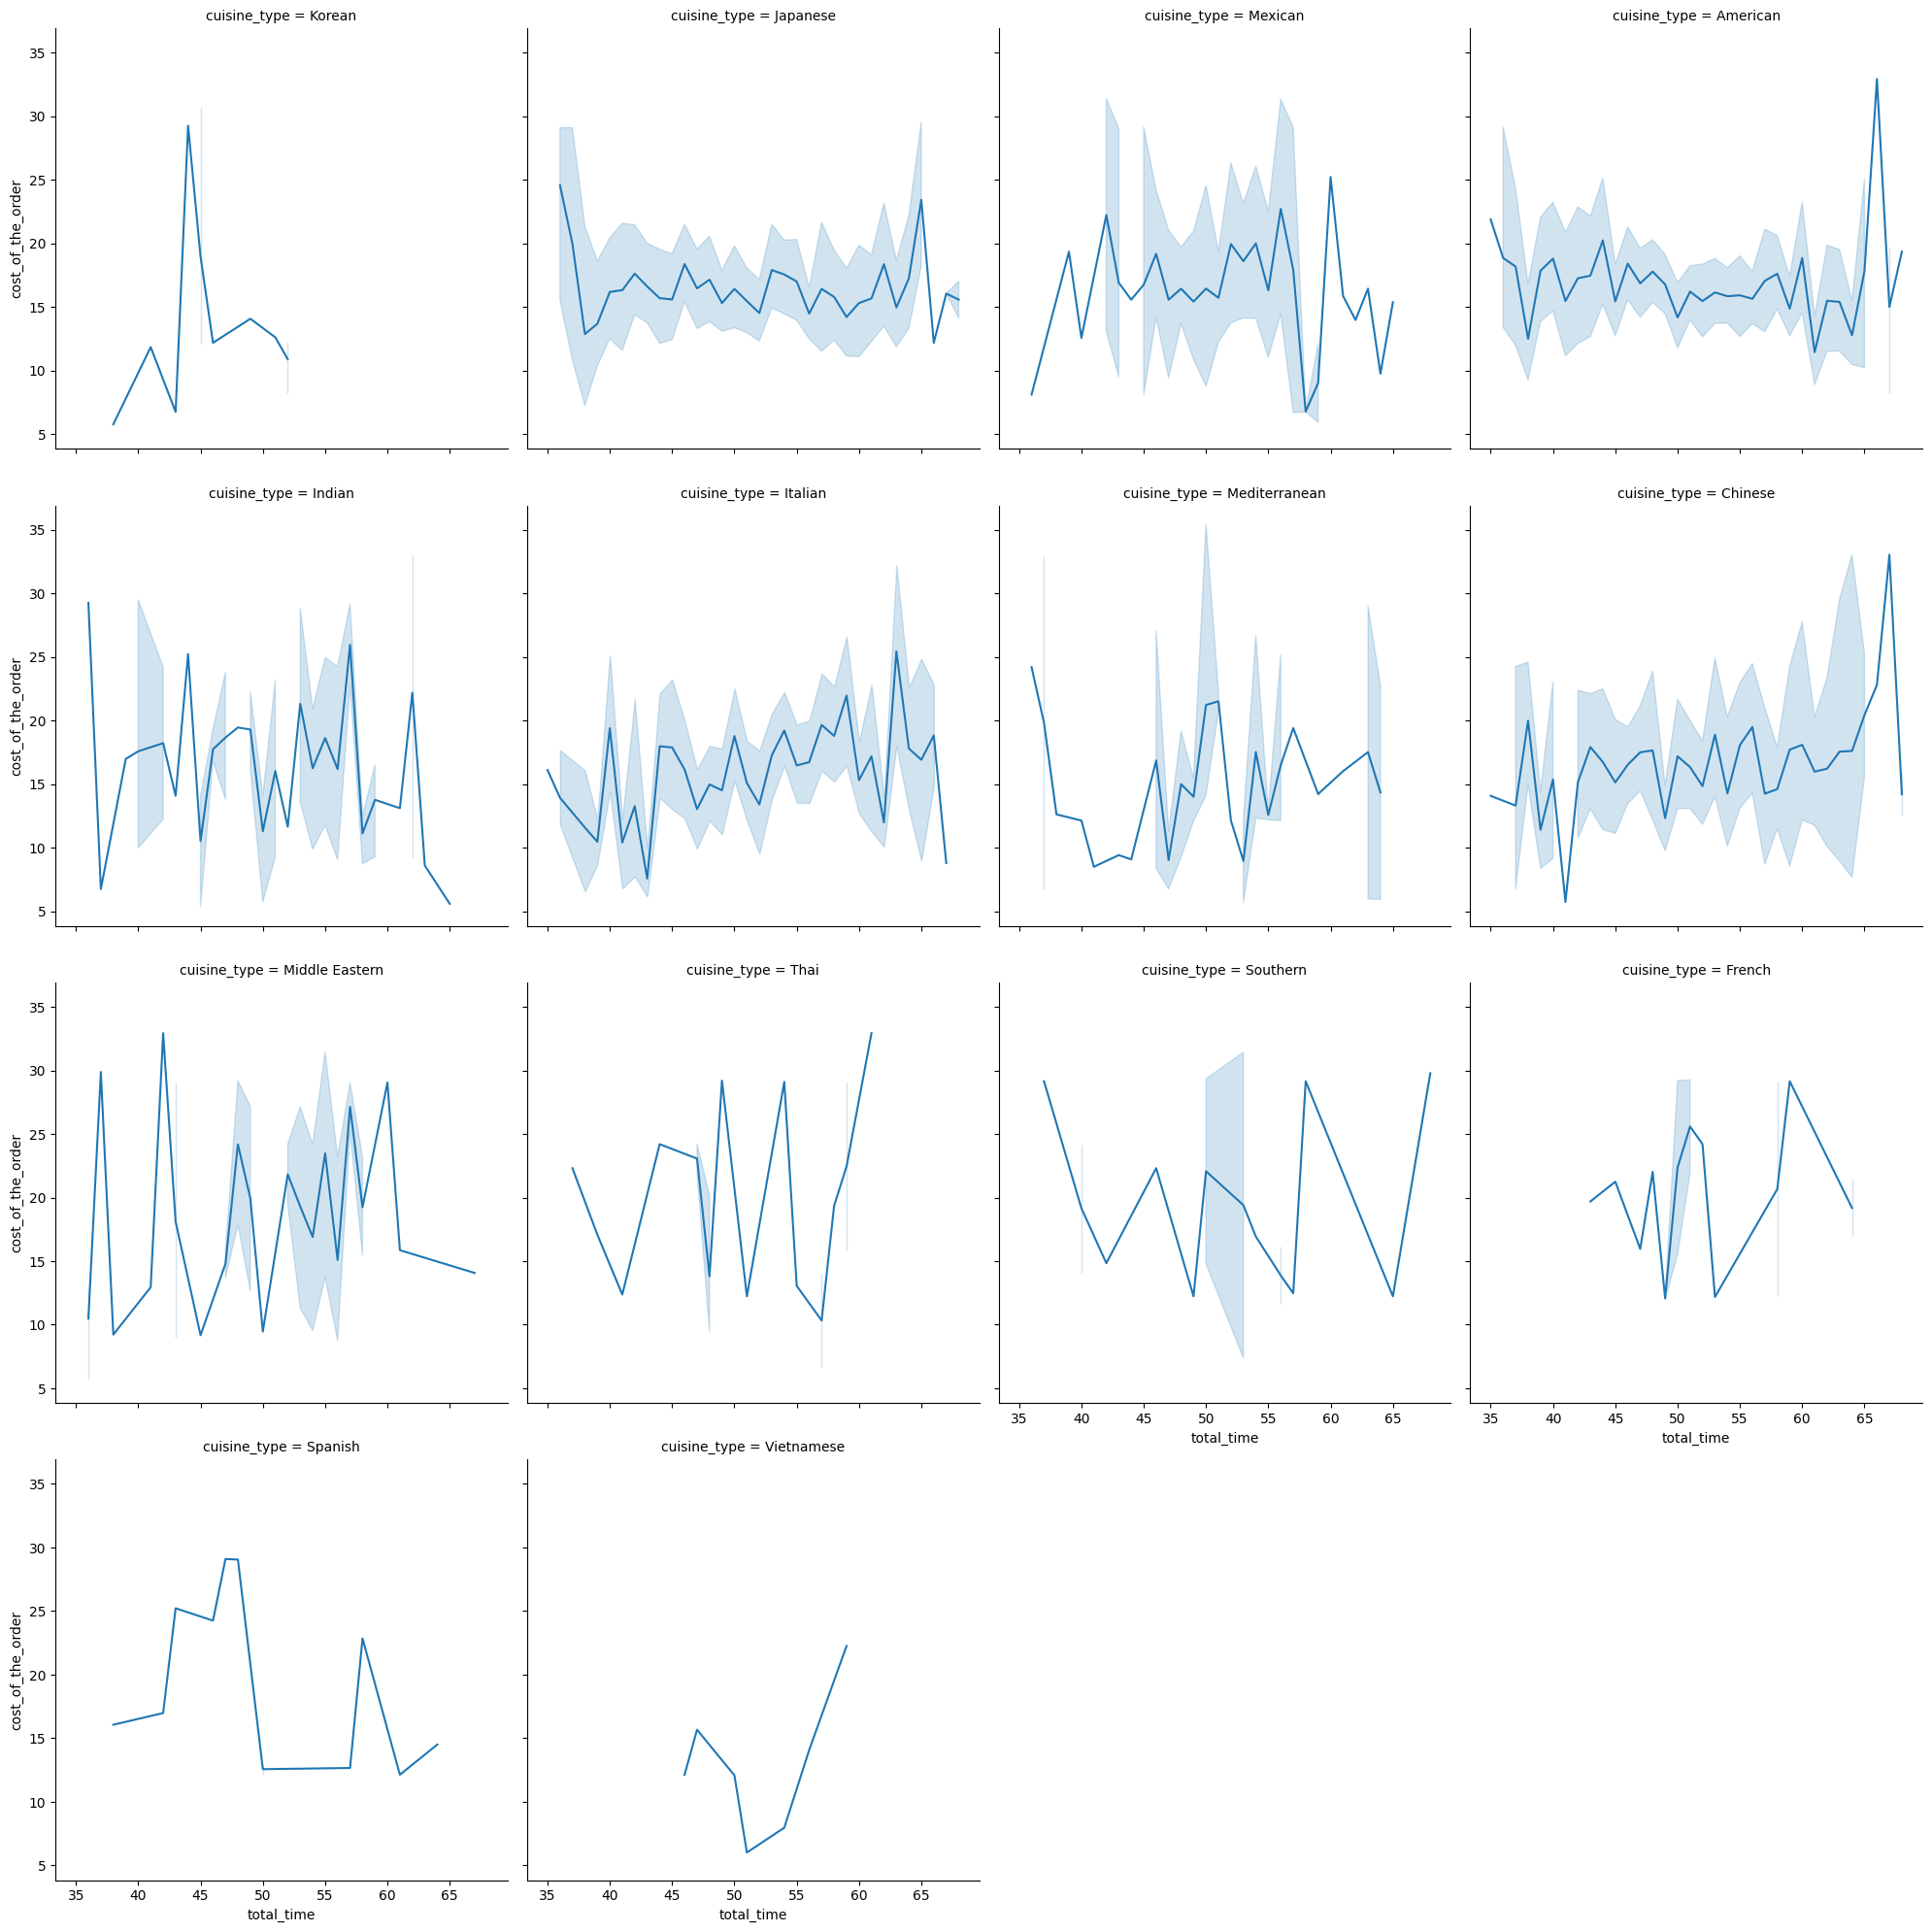

In [136]:
sns.relplot(data=df,x='total_time',y='cost_of_the_order',col='cuisine_type',kind='line', col_wrap=4)
plt.show()

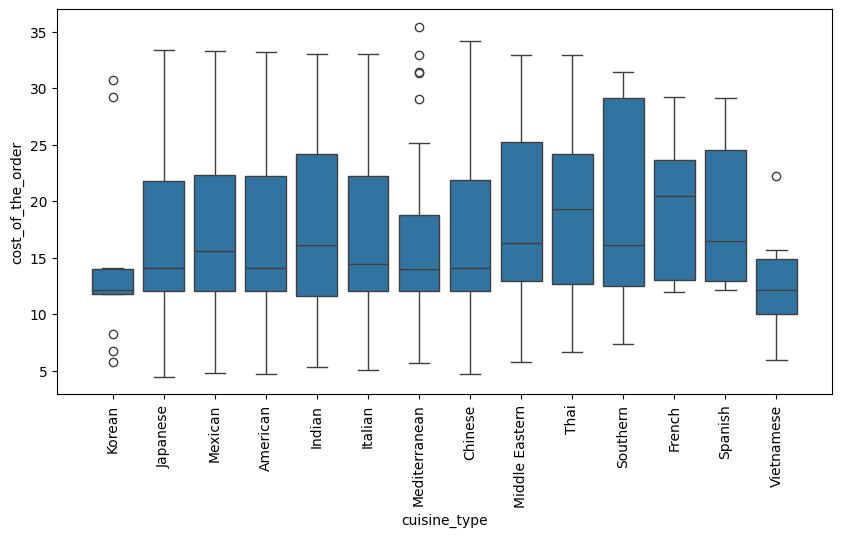

In [127]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x='cuisine_type',y='cost_of_the_order')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

####Observations:
- Mediterranean, Korean, Vietnamese cuisines have some outliers in cost of the order
- Total time plotting did not give much insights
-For Korean cuisine, food prep time is more on weekends than weekdays (possible staffing? ) But delivery time is less on weekends than weekdays.
Total Time is less on weekends vs weekdays.

Analysis on top n restaurants


<Figure size 700x200 with 0 Axes>

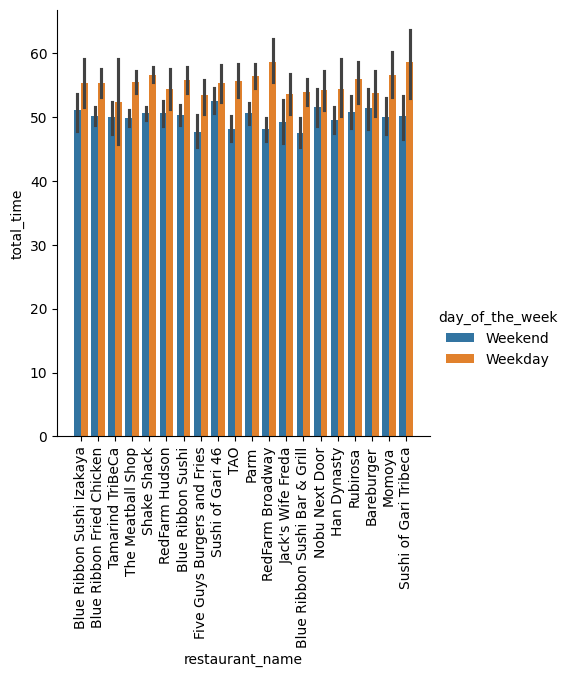

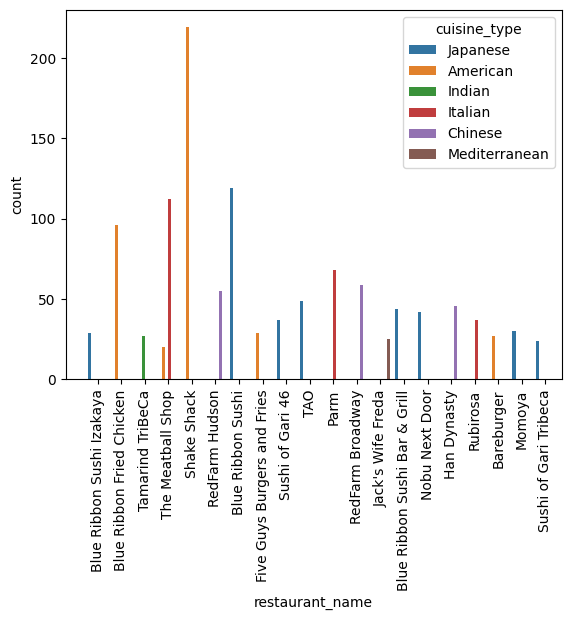




Cuisine and the number of restaurants with that cuisine: 
 cuisine_type
[American]             40
[Italian]              30
[Japanese]             29
[Chinese]              16
[Indian]               14
[Mexican]              11
[Thai]                  9
[Middle Eastern]        7
[Mediterranean]         5
[Korean]                5
[French]                3
[Vietnamese]            3
[Spanish]               3
[Southern]              2
[Italian, American]     1
Name: count, dtype: int64


In [128]:
print("Analysis on top n restaurants")
n=20
top_restaurants = df['restaurant_name'].value_counts().head(n).index
plt.figure(figsize=(7,2))
sns.catplot(data=df[df['restaurant_name'].isin(top_restaurants)], kind="bar", x='restaurant_name', y='total_time', hue='day_of_the_week')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()
print("\n\n")

sns.countplot(data=df[df['restaurant_name'].isin(top_restaurants)], x='restaurant_name', hue='cuisine_type')
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()

print("\n\n")
analyse_restaurant = df.groupby('restaurant_name')['cuisine_type'].unique().value_counts()
print("Cuisine and the number of restaurants with that cuisine: \n" , analyse_restaurant)

####Observations:
There is 1 restaurant: The Meatball Shop which classifies under 2 cuisine types: Italian and American. Derived it based on plotting and analysis using aggregate functions.

In [129]:
customer_count = df.groupby('restaurant_name')['customer_id'].agg('count')
print(customer_count)

restaurant_name
'wichcraft           1
12 Chairs            4
5 Napkin Burger      5
67 Burger            1
Alidoro              1
                    ..
Zero Otto Nove       2
brgr                 2
da Umberto           3
ilili Restaurant    18
indikitch            4
Name: customer_id, Length: 178, dtype: int64


Customers with multiple orders for the same restaurant:


,customer_id,restaurant_name,order_count
519,97991,Blue Ribbon Sushi Bar & Grill,6
96,47440,Bareburger,6
517,97806,Shake Shack,5
412,84087,The Meatball Shop,5
97,47440,Blue Ribbon Fried Chicken,4
...,...,...,...
136,52832,Donburi-ya,3
111,49631,The Meatball Shop,3
1063,277898,Blue Ribbon Fried Chicken,3
375,78939,Blue Ribbon Sushi,3


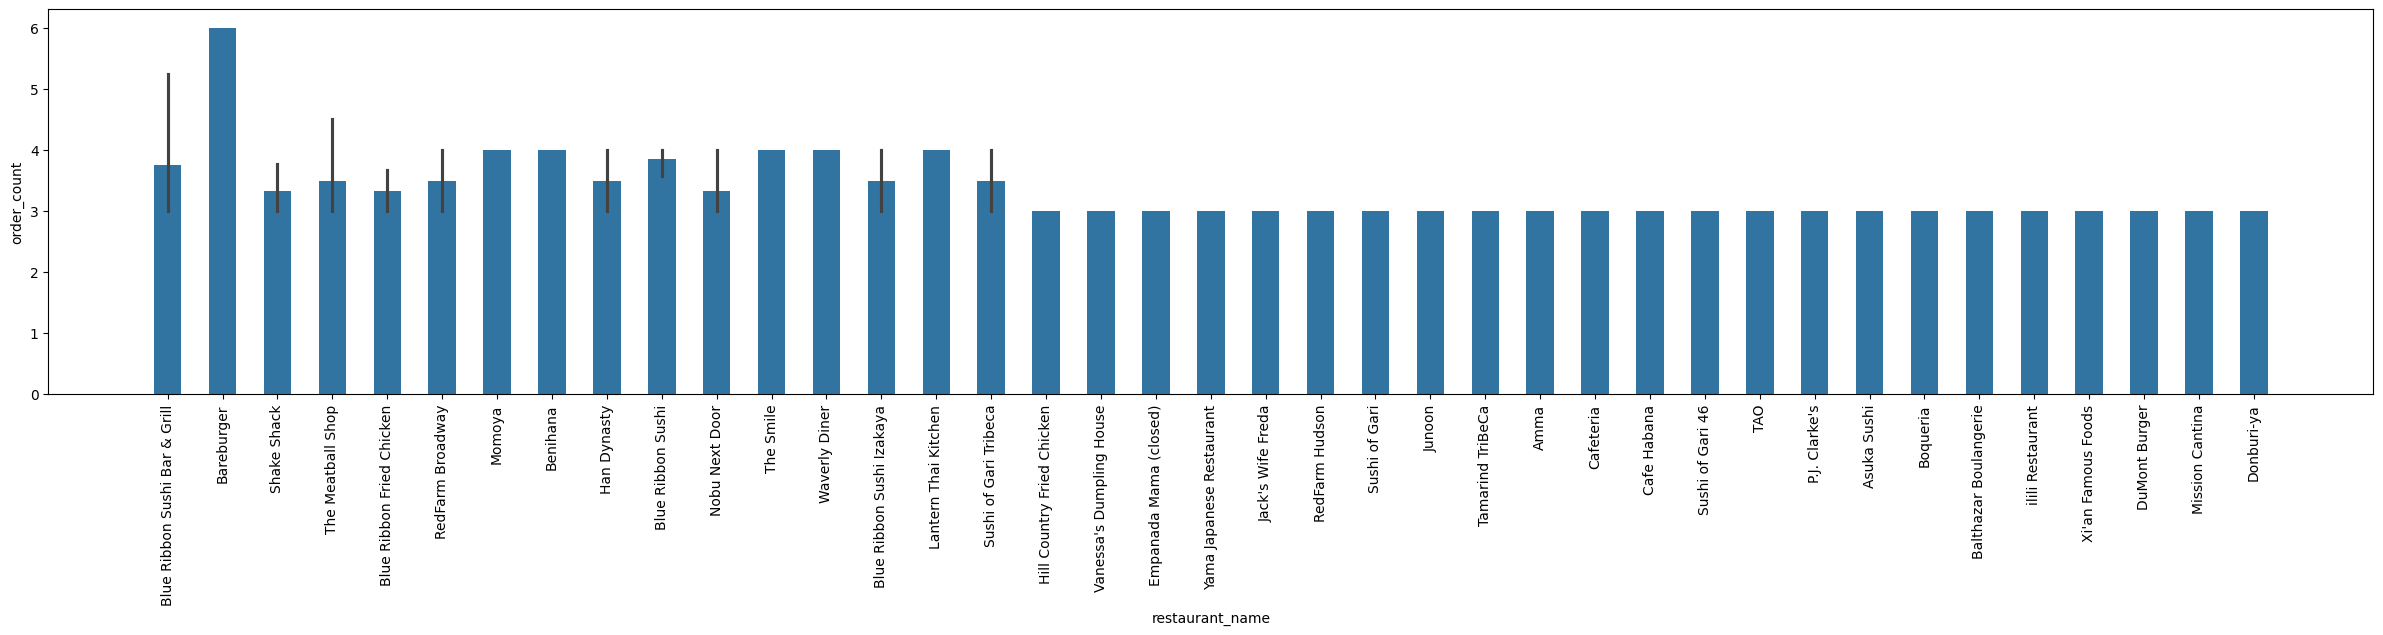

In [130]:
multiple_orders_per_restaurant = df.groupby(['customer_id', 'restaurant_name']).size().reset_index(name='order_count').sort_values(by='order_count', ascending=False)
multiple_orders_per_restaurant = multiple_orders_per_restaurant[multiple_orders_per_restaurant['order_count']>2]

print("Customers with multiple orders for the same restaurant:")
display(multiple_orders_per_restaurant)

plt.figure(figsize=(30,5))
sns.barplot(data=multiple_orders_per_restaurant[multiple_orders_per_restaurant['order_count']>2], x='restaurant_name', y='order_count', width=0.5)
plt.autoscale(enable=True, axis='x', tight=False)
plt.xticks(rotation=90)
plt.show()


####Observations:
Based on some analysis on customers who have ordered more than once from a particular restaurant, we can conclude the following:
- Customer 97991 has ordered 6 times from Blue Ribbon Sushi Bar & Grill
- Customer 47440 has ordered 6 times from Bareburger
- There are 75 customers who have ordered more than 2 times (3 or more) from the same restaurant

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [131]:
# Write the code here
restaurant_ratings = df.groupby('restaurant_name')['rating'].agg(['mean', 'count'])
restaurants_qualify_promo = restaurant_ratings[( restaurant_ratings['count'] > 50) & (restaurant_ratings['mean'] > 4)]
print(restaurants_qualify_promo)


                               mean  count
restaurant_name                           
Blue Ribbon Fried Chicken  4.328125     64
Blue Ribbon Sushi          4.219178     73
Shake Shack                4.278195    133
The Meatball Shop          4.511905     84


#### Observations:


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [132]:
# Write the code here
""" alternate way:
surcharge_25 = df[df['cost_of_the_order'] > 20]['cost_of_the_order'] * 0.25
surcharge_15 = df[(df['cost_of_the_order'] > 5) & (df['cost_of_the_order'] <= 20)]['cost_of_the_order'] * 0.15
net_revenue = surcharge_25.sum() + surcharge_15.sum()"""

def calculate_surcharge(order_cost):
    if order_cost > 20:
      return order_cost * 0.25
    elif order_cost > 5:
      return order_cost * 0.15
    else:
      return 0

df['surcharge'] = df['cost_of_the_order'].apply(calculate_surcharge)
net_revenue = df['surcharge'].sum()

print(f"The net revenue generated by the company across all orders is: ${net_revenue}")

The net revenue generated by the company across all orders is: $6166.303


#### Observations:

Calculations:
- This computation can be implemented by simple calculation or by writing a function. Commented out the simple computation method
- Defined a function to calculate the surcharge which returns the surcharges for each order based on the numerical value passed to the function.
- Using if else, first we consider > 20, then > 5 (so that the elif  restricts this data set to <=20 also ), then catch all for no surcharge(0)
- The function is applied on the each record of the cost_of_the_order column and this data is saved in a new column: surcharge
- To get the revenue generated from surcharge, we take a sum of all values in this column

Result:
- The net revenue generated through surcharge is : $6166.303

Insight:
- By scaling up the surcharge, the company can increase the revenue. This kind of surcharge can also be applied to other parameters like : weekend, popular restaurants, etc.

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [133]:
# Write the code here
df['total_time'] = df['delivery_time'] + df['food_preparation_time']
extra_time_orders = df[df['total_time']>60].shape[0]/df.shape[0]*100
print(f"Percent of orders taking more than 60 minutes is: {extra_time_orders: 0.3f}")

Percent of orders taking more than 60 minutes is:  10.537


#### **Observations**

Calculations:
- Created a new column 'total_time' by adding 'delivery_time' and 'food_preparation_time'
- Then filtered the dataframe with the condition where total time > 60. and then calculated the percentage of such rows

Result:
- 10.537% orders take more than 60 minutes

Insight:
- This is an important parameter for food delivery use case because it can have an impact on customer satisfaction. Longer the delivery time can cause the hot food to get cold.
- It also acts as a parameter to look into room for improvement as to how can the company optimise the delivery time based on such delivery times.


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

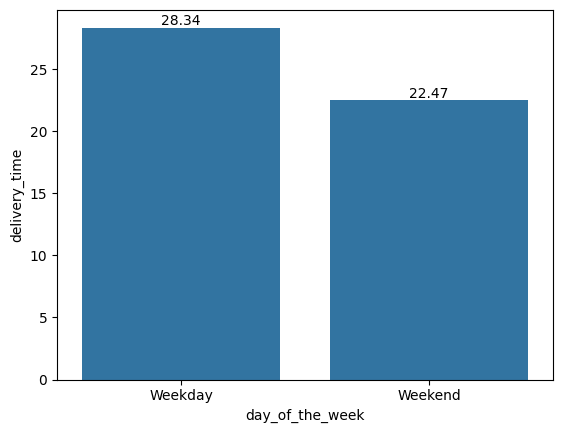

In [134]:
# Write the code here
delivery_time_analysis = df.groupby('day_of_the_week')['delivery_time'].mean()
ax = sns.barplot(data=delivery_time_analysis)
ax.bar_label(ax.containers[0])
plt.show()

#### **Observations:**
- The average delivery time on weekdays(28.34 min) is more than that on weekends(22.5) by ~6 minutes
- There can be more analysis done based on this, are there more drivers on weekends? Is there less traffic on weekends?


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
We analysed the data of 1898 orders spread over 178 restaurants and 14 cuisine types with data of 1200 customers. We can draw the following conclusions:

Statistical analysis:
- American cuisine is the most popular.
- Shake Shack is the most popular with most orders
- There is a lot of missing rating data. ( around 40%)
- The Meatball Shop is a restaurant which unusually classifies under 2 cuisine types: American and Italian
- It is difficult to find correlations in the numerical columns
- Delivery time on weekends is less.
- The top 20 restaurants by number of orders have the cuisines: Japanese, American, Indian, Italian , Chinese, Mediteranean.  Other cuisines are less popular. There are only 2 restaurants with Southern cuisine

Inferences:
- There are 40 American cuisine restaurants which is more than the number of other cuisine restaurants in the dataset. This may also contribute to American cuisine being more popular
- There are multiple ways in which the delivery app can boost it's business
 - Generate revenue by adding **surcharge** to customers
    - popular restaurants, since more customers order from them
    - if the delivery is on weekends, since the orders are more on weekends
  - Generate revenue by adding **surchage** to restaurants:
    - if the cost of the order is higher, based on Q14.
  - Get more data and traffic from customers by giving **discounts** based on
    - If the customer orders more than n times.
    - If the customer orders from less popular restaurants and rates them (to boost the rating and data)
    - If the restaurant gets n ratings with ratings greater than a particular value, based on Q13
- Restaurants with least popular cuisines and minimal orders can be dropped from service/ boosted with promotions as needed. Eg: Vietnamese cuisine has 7 orders and 3 restaurants.

  







### Recommendations:

- **Cuisine**:
- Analyse why some cuisines are more popular than others. Is it the number of restaurants for those cuisines is higher? is it the cost of the orders? Do the restaurants with these cuisines have higher ratings or more ratings data available?

- **Time**:
- Find out why the *delivery time* on weekends is less. To do this we can gather data on traffic, numbers of drivers and other data. Further we can use that data to optimise delivery time on weekdays if needed.
- There is no coorelation between *total time / delivery time / food prepartion time* and the ratings. So customer ratings are not dependent on the time taken.

- **Customers and Restaurants:**
- There are quite a few customers who order more than once or twice from the same restaurant. This should also be considered into the popularity of restaurants, like which restaurants are customer favorites for repeating customers. This can be a factor for offering promotions and marketing purposes to the customers who order more from particular restaurants

- **Discounts**:
- The discounts can be given for least popular cuisines or restaurants or based on the delivery times to boost their popularity.
- The surcharge can be increased for popular restaurants, cuisines, weekends to increase revenue.

- Additional data can be added for distance of restaurants and maps to optimize delivery times.



---